<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Experiment 11: CNN for Image Classification
This notebook demonstrates a complete workflow to build, train, and evaluate a Convolutional Neural Network (CNN) for multi-class image classification using the CIFAR-10 dataset as a substitute for garbage classification.

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

### Task 1: Load, Resize, and Normalize Dataset
We load CIFAR-10, normalize pixel values to the `[0, 1]` range, and split the data into training, validation, and testing sets.

In [2]:
# Load CIFAR-10 dataset
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Normalize images to [0, 1] range
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Split full training set into Train and Validation sets (80% train, 20% validation)
validation_split = 0.2
split_index = int(len(x_train_full) * (1 - validation_split))

x_train, x_val = x_train_full[:split_index], x_train_full[split_index:]
y_train, y_val = y_train_full[:split_index], y_train_full[split_index:]

# Define class names for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Training set: {x_train.shape}, {y_train.shape}")
print(f"Validation set: {x_val.shape}, {y_val.shape}")
print(f"Test set: {x_test.shape}, {y_test.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 424s 2us/step
Training set: (40000, 32, 32, 3), (40000, 1)
Validation set: (10000, 32, 32, 3), (10000, 1)
Test set: (10000, 32, 32, 3), (10000, 1)


### Task 2: Build the CNN Architecture
We construct a CNN model using Convolutional, MaxPooling, Flatten, and Dense layers.

In [3]:
def build_model():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3), name='conv_layer_1'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', name='conv_layer_2'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', name='conv_layer_3'),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    return model

model = build_model()
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_layer_1 (Conv2D)           │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_layer_2 (Conv2D)           │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_layer_3 (Conv2D)           │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

### Task 3: Train the Model and Plot curves
We compile the model with Sparse Categorical Crossentropy and track performance.

In [4]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=10,
                    validation_data=(x_val, y_val), batch_size=64)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 86ms/step - accuracy: 0.3995 - loss: 1.6419 - val_accuracy: 0.4958 - val_loss: 1.3934
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 81ms/step - accuracy: 0.5396 - loss: 1.2897 - val_accuracy: 0.5571 - val_loss: 1.2313
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 84ms/step - accuracy: 0.6029 - loss: 1.1268 - val_accuracy: 0.6179 - val_loss: 1.1092
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 79ms/step - accuracy: 0.6420 - loss: 1.0151 - val_accuracy: 0.6145 - val_loss: 1.0907
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 81ms/step - accuracy: 0.6711 - loss: 0.9325 - val_accuracy: 0.6622 - val_loss: 0.9666
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 49s 78ms/step - accuracy: 0.6956 - loss: 0.8685 - val_accuracy: 0.6667 - val_loss: 0.9620
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 80ms/step - accuracy: 0.7168 - loss: 0.8102 - val_accuracy: 0.6921 - val_loss: 0.8971
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 80ms/step - accuracy: 0.7369 - loss: 0.7519 - 

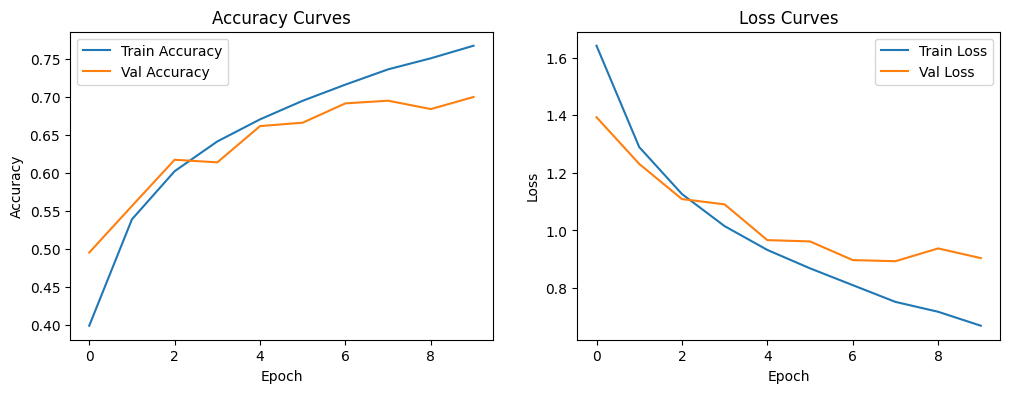

In [5]:
# Plot Training & Validation Loss and Accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy Curves')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curves')

plt.show()

### Task 4: Evaluation, Confusion Matrix, and Sample Misclassifications

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step


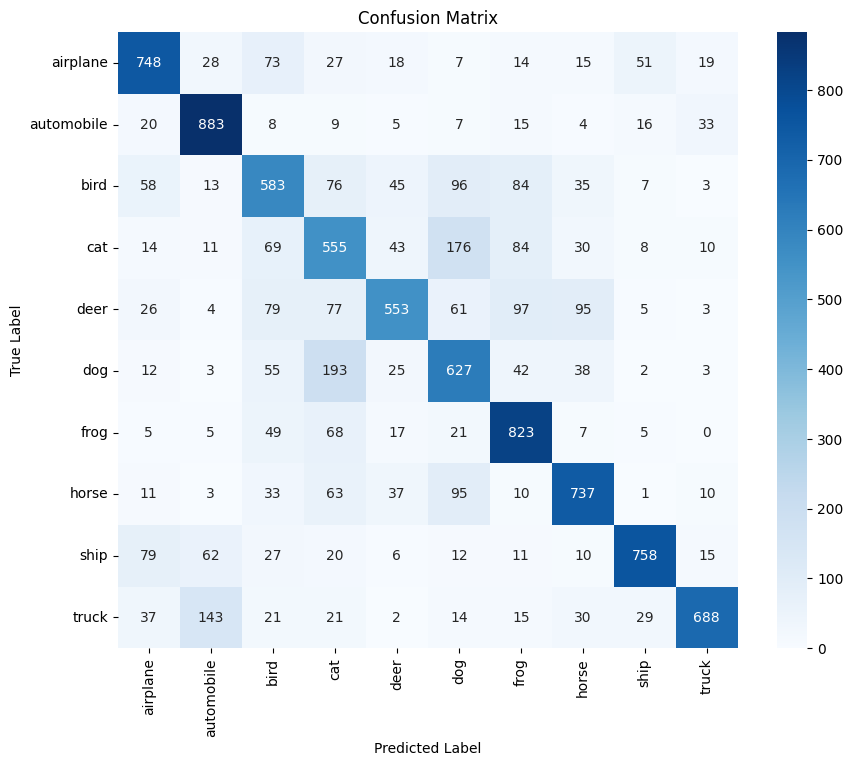

In [6]:
# Get model predictions
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

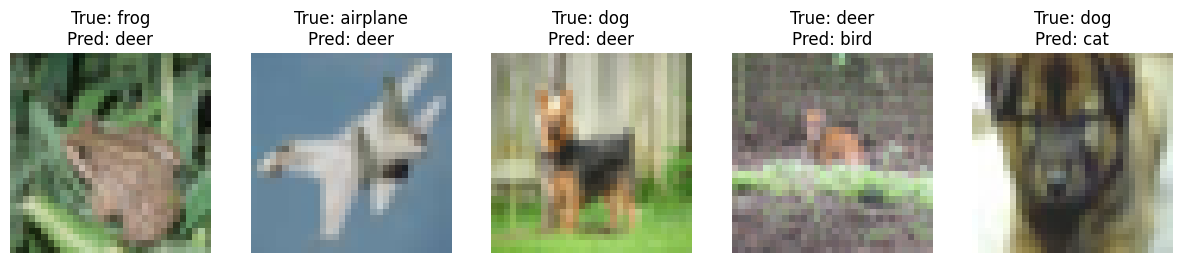

In [7]:
# Find misclassified indices
misclassified_idx = np.where(y_pred != y_test.squeeze())[0]

# Plot 5 sample misclassifications
plt.figure(figsize=(15, 3))
for i, idx in enumerate(misclassified_idx[:5]):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_test[idx])
    plt.title(f"True: {class_names[y_test[idx][0]]}\nPred: {class_names[y_pred[idx]]}")
    plt.axis('off')
plt.show()

### Task 5: Visualize Feature Maps of the First Convolution Layer

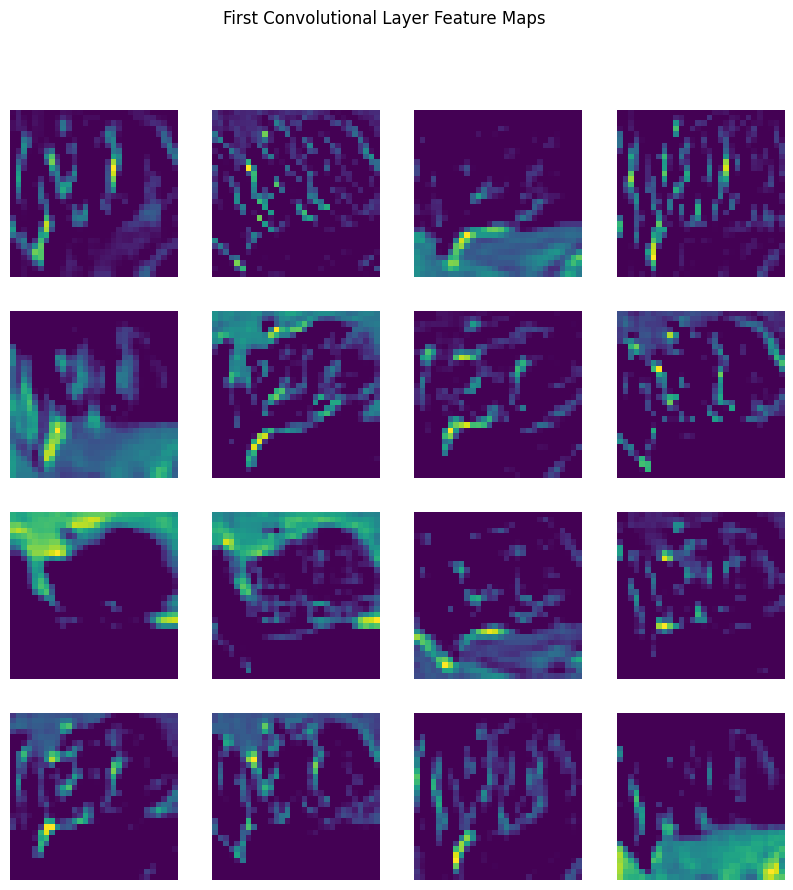

In [10]:
# Access the first layer directly to extract features
# We can run the layer directly on our input image to obtain the activation
sample_img = np.expand_dims(x_test[0], axis=0)

# Get the first convolutional layer
conv_layer_1 = model.get_layer('conv_layer_1')

# Pass the image through the first layer
feature_maps = conv_layer_1(sample_img)

# Plot the feature maps
plt.figure(figsize=(10, 10))
for i in range(16): # Show the first 16 filters
    plt.subplot(4, 4, i+1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.axis('off')
plt.suptitle('First Convolutional Layer Feature Maps')
plt.show()